# Assignment 2 – Section B: Robust classification with limited data (CIFAR-10)

A small CNN with Inception modules is trained from scratch on 500 CIFAR-10 images (400 train / 100 validation) and tested on a clean and a shifted test set. All hyper-parameters are chosen on the validation split only, augmentation is applied on the fly to training data only, training is limited to 60 epochs, and every result is the mean ± std over 3 seeds.

In [2]:
import os, math, time, random
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import confusion_matrix

torch.set_num_threads(1)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
os.makedirs("figures", exist_ok=True)

SEEDS      = [0, 1, 2]     
TUNE_SEEDS = [100, 101]   
SPLIT_SEED = 0             
SHIFT_SEED = 2024         
EPOCHS     = 60         
BATCH      = 32

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)

## 1. Data

In [3]:
import torchvision
tr = torchvision.datasets.CIFAR10("./data", train=True,  download=True)
te = torchvision.datasets.CIFAR10("./data", train=False, download=True)
Xtr_all, ytr_all, Xte_all, yte_all, CLASSES = tr.data, np.array(tr.targets), te.data, np.array(te.targets), tr.classes
to_tensor = lambda X: torch.from_numpy(X).permute(0, 3, 1, 2).float().div(255.)   # uint8 NHWC -> float NCHW in [0,1]

# train_small: 50 images per class (fixed seed), then a stratified 400 train / 100 validation split
rng = np.random.RandomState(SPLIT_SEED)
small_idx = np.concatenate([rng.choice(np.where(ytr_all == c)[0], 50, replace=False) for c in range(10)])
tr_idx, va_idx = [], []
for c in range(10):
    ci = rng.permutation(small_idx[ytr_all[small_idx] == c])
    tr_idx += list(ci[:40]); va_idx += list(ci[40:])
tr_idx, va_idx = np.array(tr_idx), np.array(va_idx)

X_train, y_train = to_tensor(Xtr_all[tr_idx]), torch.from_numpy(ytr_all[tr_idx]).long()
X_val,   y_val   = to_tensor(Xtr_all[va_idx]), torch.from_numpy(ytr_all[va_idx]).long()
X_clean, y_test  = to_tensor(Xte_all), torch.from_numpy(yte_all).long()      # clean_test (10,000 images)

assert len(set(tr_idx) & set(va_idx)) == 0 and len(tr_idx) == 400 and len(va_idx) == 100
CH_MEAN = X_train.mean(dim=(0, 2, 3)); CH_STD = X_train.std(dim=(0, 2, 3))   # statistics of the 400 train images only
print("train", tuple(X_train.shape), "| val", tuple(X_val.shape), "| clean_test", tuple(X_clean.shape))

train (400, 3, 32, 32) | val (100, 3, 32, 32) | clean_test (10000, 3, 32, 32)


### The shifted test set
`shifted_test` is built once from the 10,000 clean test images with a fixed, seeded corruption pipeline: rotation (±25°), brightness/contrast, blur, noise, one rectangular occlusion (~25 % of the image) and a hidden corruption (random RGB channel swap). A shifted version of the 100 validation images (listed corruptions only, no hidden one, different seed) is also built so that models can be compared on robustness without touching test data.

shifted_test (10000, 3, 32, 32) | mean occlusion 25.0% | swapped: 51% | blurred: 30%


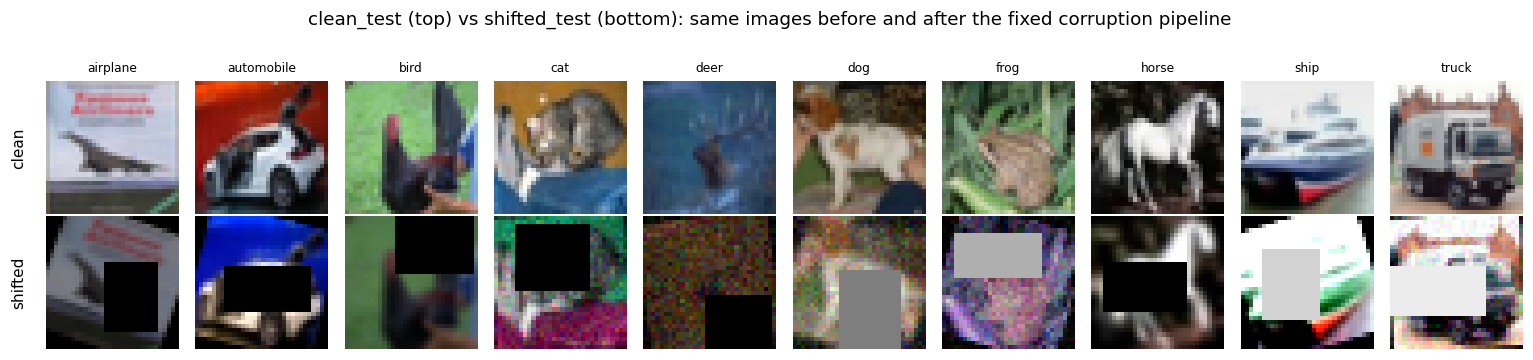

In [5]:
def corrupt(x, seed, comps=("rot", "bc", "blur", "noise", "occ", "swap"), p_blur=0.3, p_noise=0.5, p_swap=0.5):
    """Fixed, seeded corruption of a float NCHW batch in [0,1]. Returns (corrupted batch, per-image metadata)."""
    g = torch.Generator().manual_seed(seed)
    R = lambda *s: torch.rand(*s, generator=g)
    N = x.size(0); meta = {}; x = x.clone()
    if "rot" in comps:                                       # rotation up to +-25 degrees
        ang = (R(N) * 2 - 1) * 25; a = ang * math.pi / 180
        th = torch.zeros(N, 2, 3)
        th[:, 0, 0] = torch.cos(a); th[:, 0, 1] = -torch.sin(a); th[:, 1, 0] = torch.sin(a); th[:, 1, 1] = torch.cos(a)
        x = F.grid_sample(x, F.affine_grid(th, x.shape, align_corners=False), padding_mode="zeros", align_corners=False)
        meta["rot"] = ang
    if "bc" in comps:                                        # brightness 0.5-1.5 (dark..bright), contrast 0.6-1.4
        b, c = 0.5 + R(N), 0.6 + R(N) * 0.8
        x = x * b.view(-1, 1, 1, 1); m = x.mean(dim=(1, 2, 3), keepdim=True)
        x = ((x - m) * c.view(-1, 1, 1, 1) + m).clamp(0, 1)
        meta["bright"], meta["contrast"] = b, c
    if "blur" in comps:                                      # 3x3 Gaussian blur
        k = torch.tensor([1., 2., 1.]); k = (k[:, None] * k[None]); k = (k / k.sum()).view(1, 1, 3, 3).repeat(3, 1, 1, 1)
        bl = F.conv2d(F.pad(x, (1, 1, 1, 1), mode="reflect"), k, groups=3)
        do = R(N) < p_blur; x = torch.where(do.view(-1, 1, 1, 1), bl, x); meta["blur"] = do
    if "noise" in comps:                                     # additive Gaussian noise, sigma = 0.06
        nz = torch.randn(x.shape, generator=g) * 0.06
        do = R(N) < p_noise; x = torch.where(do.view(-1, 1, 1, 1), (x + nz).clamp(0, 1), x); meta["noise"] = do
    if "occ" in comps:                                       # one rectangle covering ~20-30% of the image
        area = 0.20 + R(N) * 0.10; ar = torch.exp((R(N) * 2 - 1) * math.log(2.0))
        h = (torch.sqrt(area * ar) * 32).round().clamp(4, 32).long(); w = (area * 1024 / h).round().clamp(4, 32).long()
        top = (R(N) * (32 - h + 1).float()).long(); left = (R(N) * (32 - w + 1).float()).long()
        fill = (R(N) < 0.5).float() * R(N)                   
        ys, xs = torch.arange(32).view(1, 32, 1), torch.arange(32).view(1, 1, 32)
        mask = (ys >= top.view(-1, 1, 1)) & (ys < (top + h).view(-1, 1, 1)) & (xs >= left.view(-1, 1, 1)) & (xs < (left + w).view(-1, 1, 1))
        x = torch.where(mask.unsqueeze(1), fill.view(-1, 1, 1, 1).expand_as(x), x); meta["occ"] = mask.float().mean(dim=(1, 2))
    if "swap" in comps:                                     #hidden corruption
        perms = torch.tensor([[1, 0, 2], [2, 1, 0], [0, 2, 1], [1, 2, 0], [2, 0, 1]])
        do = R(N) < p_swap; pick = perms[(R(N) * 5).long().clamp(max=4)]
        sw = torch.gather(x, 1, pick.view(N, 3, 1, 1).expand(-1, -1, 32, 32))
        x = torch.where(do.view(-1, 1, 1, 1), sw, x); meta["swap"] = do
    return x.clamp(0, 1), meta
X_val_shift, _ = corrupt(X_val, SHIFT_SEED + 7, comps=("rot", "bc", "blur", "noise", "occ"))
X_shift, META = corrupt(X_clean, SHIFT_SEED)      # shifted_test (fixed once, never used for training or tuning)
print("shifted_test", tuple(X_shift.shape), "| mean occlusion %.1f%%" % (100 * META["occ"].mean()),
      "| swapped: %.0f%%" % (100 * META["swap"].float().mean()), "| blurred: %.0f%%" % (100 * META["blur"].float().mean()))

fig, ax = plt.subplots(2, 10, figsize=(14, 3.2))
for j in range(10):
    i = int(np.where(yte_all == j)[0][0])
    ax[0, j].imshow(X_clean[i].permute(1, 2, 0)); ax[1, j].imshow(X_shift[i].permute(1, 2, 0))
    ax[0, j].set_title(CLASSES[j], fontsize=8)
    for r in (0, 1): ax[r, j].axis("off")
ax[0, 0].text(-0.15, 0.5, "clean", transform=ax[0, 0].transAxes, rotation=90, va="center", ha="right")
ax[1, 0].text(-0.15, 0.5, "shifted", transform=ax[1, 0].transAxes, rotation=90, va="center", ha="right")
fig.suptitle("clean_test (top) vs shifted_test (bottom): same images before and after the fixed corruption pipeline", y=1.02)
plt.tight_layout(); plt.savefig("figures/data_samples.png", bbox_inches="tight"); plt.show()

## 2. Model: small CNN with an Inception module
Stem (3×3 conv → pool → 3×3 conv) → two **Inception modules** (parallel 1×1, 1×1→3×3, 1×1→5×5 and pool→1×1 branches, concatenated) with max-pooling between them → global average pooling → dropout → linear layer. BatchNorm follows every convolution.

In [6]:
def cbr(cin, cout, k):
    return nn.Sequential(nn.Conv2d(cin, cout, k, padding=k // 2, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))

class Inception(nn.Module):
    """parallel 1x1 | 1x1->3x3 | 1x1->5x5 | maxpool->1x1, concatenated along channels"""
    def __init__(self, cin, c1, c3r, c3, c5r, c5, cp):
        super().__init__()
        self.b1 = cbr(cin, c1, 1)
        self.b2 = nn.Sequential(cbr(cin, c3r, 1), cbr(c3r, c3, 3))
        self.b3 = nn.Sequential(cbr(cin, c5r, 1), cbr(c5r, c5, 5))
        self.b4 = nn.Sequential(nn.MaxPool2d(3, 1, 1), cbr(cin, cp, 1))
    def forward(self, x):
        return torch.cat([self.b1(x), self.b2(x), self.b3(x), self.b4(x)], 1)

class Net(nn.Module):
    def __init__(self, dropout=0.3, n_classes=10):
        super().__init__()
        self.register_buffer("mean", CH_MEAN.view(1, 3, 1, 1)); self.register_buffer("std", CH_STD.view(1, 3, 1, 1))
        self.stem  = nn.Sequential(cbr(3, 32, 3), nn.MaxPool2d(2), cbr(32, 48, 3))     
        self.inc1  = Inception(48, 16, 16, 24, 8, 12, 12)                            
        self.pool1 = nn.MaxPool2d(2)                                                   
        self.inc2  = Inception(64, 24, 24, 32, 8, 16, 16)                             
        self.pool2 = nn.MaxPool2d(2)                                                  
        self.drop  = nn.Dropout(dropout)                                               
        self.fc    = nn.Linear(88, n_classes)
    def forward(self, x):
        x = (x - self.mean) / self.std                                              
        x = self.pool1(self.inc1(self.stem(x)))
        x = self.pool2(self.inc2(x))
        return self.fc(self.drop(x.mean(dim=(2, 3))))                                 

PARAMS = sum(p.numel() for p in Net().parameters() if p.requires_grad)
assert PARAMS <= 1_000_000
print(f"trainable parameters: {PARAMS:,}  (limit 1,000,000)")

trainable parameters: 39,226  (limit 1,000,000)


## Augumentation

In [7]:
def aug_geometric(x, max_rot=30, max_shift=4, scale=(0.9, 1.1), hflip=True):
    """random rotation + translation (= random crop with 4px padding) + zoom + horizontal flip, in one affine warp"""
    N = x.size(0)
    a = (torch.rand(N) * 2 - 1) * max_rot * math.pi / 180
    s = scale[0] + torch.rand(N) * (scale[1] - scale[0])
    tx, ty = [(torch.rand(N) * 2 - 1) * max_shift * 2 / 32 for _ in range(2)]
    fx = torch.where(torch.rand(N) < 0.5, -1.0, 1.0) if hflip else torch.ones(N)
    c, sn = torch.cos(a) / s, torch.sin(a) / s
    th = torch.zeros(N, 2, 3)
    th[:, 0, 0] = c * fx; th[:, 0, 1] = -sn; th[:, 0, 2] = tx
    th[:, 1, 0] = sn * fx; th[:, 1, 1] = c;  th[:, 1, 2] = ty
    return F.grid_sample(x, F.affine_grid(th, x.shape, align_corners=False), padding_mode="zeros", align_corners=False)

_K = torch.tensor([1., 2., 1.]); _K = (_K[:, None] * _K[None]); _K = (_K / _K.sum()).view(1, 1, 3, 3).repeat(3, 1, 1, 1)
def aug_photometric(x, bright=(0.5, 1.5), contrast=(0.6, 1.4), sat=(0.5, 1.5), p_gray=0.2, p_blur=0.25, p_noise=0.5, sigma_max=0.08):
    """colour jitter (brightness, contrast, saturation) + random grayscale + blur + Gaussian noise"""
    N = x.size(0); u = lambda lo, hi: (lo + torch.rand(N) * (hi - lo)).view(-1, 1, 1, 1)
    gray = lambda t: (0.299 * t[:, 0:1] + 0.587 * t[:, 1:2] + 0.114 * t[:, 2:3])
    x = x * u(*bright)
    m = x.mean(dim=(1, 2, 3), keepdim=True); x = (x - m) * u(*contrast) + m
    g = gray(x); x = (x - g) * u(*sat) + g
    x = torch.where((torch.rand(N) < p_gray).view(-1, 1, 1, 1), gray(x).expand_as(x), x)
    x = torch.where((torch.rand(N) < p_blur).view(-1, 1, 1, 1), F.conv2d(F.pad(x, (1, 1, 1, 1), mode="reflect"), _K, groups=3), x)
    x = torch.where((torch.rand(N) < p_noise).view(-1, 1, 1, 1), x + torch.randn_like(x) * torch.rand(N).view(-1, 1, 1, 1) * sigma_max, x)
    return x.clamp(0, 1)

def aug_cutout(x, p=0.5, area=(0.05, 0.30)):
    """Cutout / Random Erasing: with probability p paint one random rectangle (5-30% of the image) with a random gray"""
    N = x.size(0); a = area[0] + torch.rand(N) * (area[1] - area[0]); ar = torch.exp((torch.rand(N) * 2 - 1) * math.log(2.0))
    h = (torch.sqrt(a * ar) * 32).round().clamp(2, 32).long(); w = (a * 1024 / h).round().clamp(2, 32).long()
    top = (torch.rand(N) * (32 - h + 1).float()).long(); left = (torch.rand(N) * (32 - w + 1).float()).long()
    ys, xs = torch.arange(32).view(1, 32, 1), torch.arange(32).view(1, 1, 32)
    mask = (ys >= top.view(-1, 1, 1)) & (ys < (top + h).view(-1, 1, 1)) & (xs >= left.view(-1, 1, 1)) & (xs < (left + w).view(-1, 1, 1))
    mask = mask & (torch.rand(N) < p).view(-1, 1, 1)
    return torch.where(mask.unsqueeze(1), torch.rand(N).view(-1, 1, 1, 1).expand_as(x), x)

def cutmix(x, y, alpha=1.0):
    """paste a random box from a shuffled copy of the batch; labels are mixed in proportion to the pasted area"""
    lam = np.random.beta(alpha, alpha); idx = torch.randperm(x.size(0)); H = W = x.size(2)
    rh, rw = int(H * math.sqrt(1 - lam)), int(W * math.sqrt(1 - lam)); cy, cx = np.random.randint(H), np.random.randint(W)
    y1, y2, x1, x2 = max(cy - rh // 2, 0), min(cy + rh // 2, H), max(cx - rw // 2, 0), min(cx + rw // 2, W)
    x = x.clone(); x[:, :, y1:y2, x1:x2] = x[idx, :, y1:y2, x1:x2]
    return x, y, y[idx], 1 - (y2 - y1) * (x2 - x1) / (H * W)
GEO    = dict(max_rot=30, max_shift=4, scale=(0.9, 1.1), hflip=True)
PHOTO  = dict(bright=(0.5, 1.5), contrast=(0.6, 1.4), sat=(0.5, 1.5), p_gray=0.2, p_blur=0.25, p_noise=0.5, sigma_max=0.08)
CUTOUT = dict(p=0.5, area=(0.05, 0.30))
AUG = {"noaug": {}, "geo": dict(geo=GEO), "photo": dict(photo=PHOTO), "geo_photo": dict(geo=GEO, photo=PHOTO),
       "cutout": dict(geo=GEO, photo=PHOTO, cutout=CUTOUT), "cutmix_ls": dict(geo=GEO, photo=PHOTO, cutout=CUTOUT, cutmix=0.5)}  # cutmix = probability per batch

def apply_aug(x, y, aug):
    """returns (x_aug, y_a, y_b, lam); without CutMix y_b = y_a and lam = 1"""
    if "geo" in aug:    x = aug_geometric(x, **aug["geo"])
    if "photo" in aug:  x = aug_photometric(x, **aug["photo"])
    if "cutout" in aug: x = aug_cutout(x, **aug["cutout"])
    if aug.get("cutmix", 0) > 0 and np.random.rand() < aug["cutmix"]:
        return cutmix(x, y)
    return x, y, y, 1.0

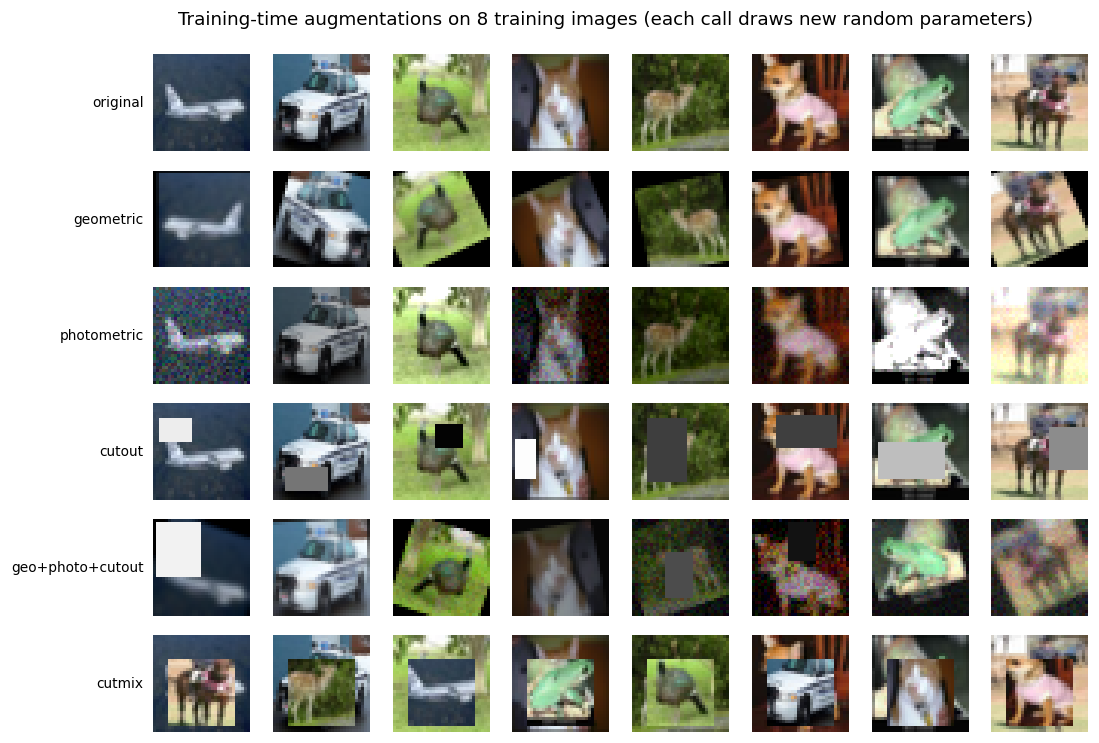

In [8]:
# visual check of every augmentation on a few training images (training images only, never test images)
set_seed(0)
demo = X_train[[0, 41, 90, 130, 170, 215, 260, 300]]
rows = [("original", demo), ("geometric", aug_geometric(demo, **GEO)), ("photometric", aug_photometric(demo, **PHOTO)),
        ("cutout", aug_cutout(demo, p=1.0)), ("geo+photo+cutout", aug_cutout(aug_photometric(aug_geometric(demo, **GEO), **PHOTO), **CUTOUT)),
        ("cutmix", cutmix(demo, y_train[[0, 41, 90, 130, 170, 215, 260, 300]])[0])]
fig, ax = plt.subplots(len(rows), 8, figsize=(11, 8))
for r, (name, imgs) in enumerate(rows):
    for j in range(8):
        ax[r, j].imshow(imgs[j].permute(1, 2, 0).clamp(0, 1)); ax[r, j].axis("off")
    ax[r, 0].text(-0.1, 0.5, name, transform=ax[r, 0].transAxes, ha="right", va="center", fontsize=9)
fig.suptitle("Training-time augmentations on 8 training images (each call draws new random parameters)", y=0.93)
plt.savefig("figures/augmentations.png", bbox_inches="tight"); plt.show()

## 4. Training and evaluation

In [9]:
@torch.no_grad()
def predict(model, X, bs=1000):
    model.eval(); return torch.cat([model(X[i:i + bs]) for i in range(0, len(X), bs)])

def accuracy(logits, y): return (logits.argmax(1) == y).float().mean().item()

RUNS = {}   

def run_experiment(name, seed, aug=None, lr=3e-3, wd=1e-2, dropout=0.3, ls=0.0, sched="cos", eval_test=True):
    """Train one model. The checkpoint with the best VALIDATION accuracy is kept (early stopping); test sets are used only for the final report."""
    aug = aug or {}; set_seed(seed); t0 = time.time()
    model = Net(dropout); opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    steps = EPOCHS * math.ceil(len(X_train) / BATCH)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=steps) if sched == "cos" else None
    hist = dict(train_loss=[], train_acc=[], val_loss=[], val_acc=[]); best = (-1, 1e9, None, 0)
    for ep in range(EPOCHS):
        model.train(); perm = torch.randperm(len(X_train)); tl = tc = 0.0
        for i in range(0, len(perm), BATCH):
            b = perm[i:i + BATCH]
            xb, ya, yb, lam = apply_aug(X_train[b], y_train[b], aug)         
            out = model(xb)
            loss = lam * F.cross_entropy(out, ya, label_smoothing=ls) + (1 - lam) * F.cross_entropy(out, yb, label_smoothing=ls)
            opt.zero_grad(); loss.backward(); opt.step()
            if scheduler: scheduler.step()
            tl += loss.item() * len(b); tc += (out.argmax(1) == ya).sum().item()
        vo = predict(model, X_val); vl = F.cross_entropy(vo, y_val).item(); va = accuracy(vo, y_val)
        hist["train_loss"].append(tl / len(perm)); hist["train_acc"].append(tc / len(perm)); hist["val_loss"].append(vl); hist["val_acc"].append(va)
        if va > best[0] or (va == best[0] and vl < best[1]):                  
            best = (va, vl, {k: v.clone() for k, v in model.state_dict().items()}, ep + 1)
    model.load_state_dict(best[2])
    res = dict(hist=hist, best_epoch=best[3], state=best[2], train=accuracy(predict(model, X_train), y_train), val=best[0],
               valshift=accuracy(predict(model, X_val_shift), y_val), clean=None, shifted=None)
    if eval_test:
        res["clean"] = accuracy(predict(model, X_clean), y_test); res["shifted"] = accuracy(predict(model, X_shift), y_test)
    RUNS[f"{name}|{seed}"] = res
    f = lambda v: "  -  " if v is None else f"{100 * v:5.1f}"
    print(f"{name:<14} seed {seed:<3} best epoch {best[3]:>2} | train {f(res['train'])} val {f(res['val'])} clean {f(res['clean'])} shifted {f(res['shifted'])} | {time.time() - t0:.0f}s")
    return res

def load_model(res):
    m = Net(); m.load_state_dict(res["state"]); return m.eval()

def summarize(name):
    rs = [RUNS[f"{name}|{s}"] for s in SEEDS]
    return {k: (100 * np.mean([r[k] for r in rs]), 100 * np.std([r[k] for r in rs])) for k in ("train", "val", "valshift", "clean", "shifted")}

fmt = lambda t: f"{t[0]:.1f} ± {t[1]:.1f}"

# Part A – Baseline (no augmentation)

baseline       seed 0   best epoch  9 | train  70.2 val  46.0 clean  38.9 shifted  18.7 | 96s
baseline       seed 1   best epoch 42 | train  99.3 val  46.0 clean  39.0 shifted  15.9 | 98s
baseline       seed 2   best epoch 33 | train  98.8 val  43.0 clean  39.1 shifted  17.1 | 104s


,"Accuracy % (mean ± std, 3 seeds)"
Training (clean 400),89.4 ± 13.6
Validation (100),45.0 ± 1.4
"Clean test (10,000)",39.0 ± 0.1
"Shifted test (10,000)",17.2 ± 1.1


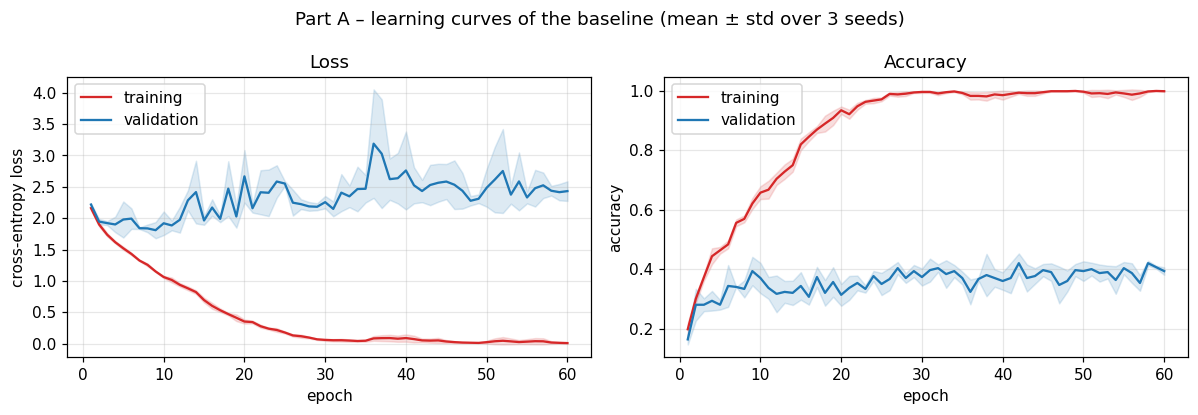

,"Accuracy % (mean ± std, 3 seeds)"
Training (clean 400),100.0 ± 0.0
Validation (100),45.7 ± 2.1
"Clean test (10,000)",41.5 ± 1.7
"Shifted test (10,000)",17.0 ± 0.9


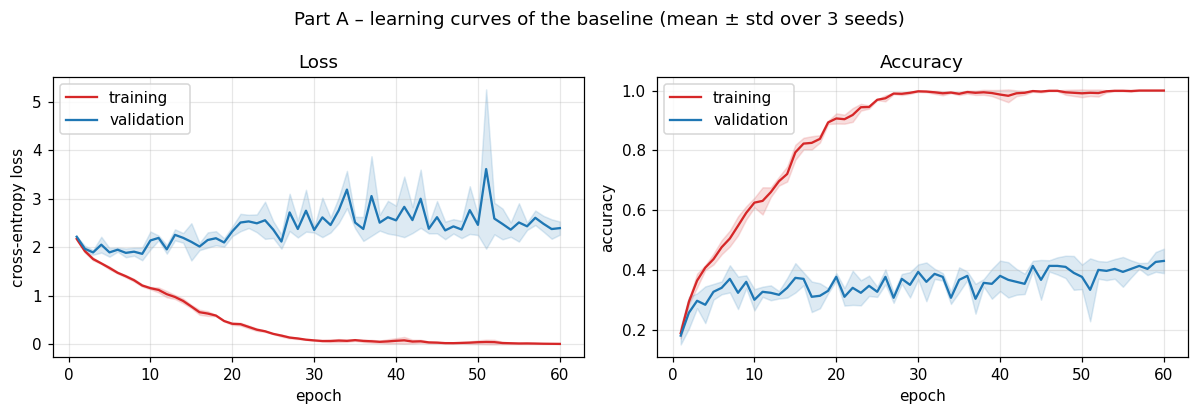

In [10]:
for s in SEEDS: run_experiment("baseline", s, aug=None, lr=3e-3, wd=0.0, dropout=0.0, sched="const")
sb = summarize("baseline")
display(pd.DataFrame({"Accuracy % (mean ± std, 3 seeds)": {"Training (clean 400)": fmt(sb["train"]), "Validation (100)": fmt(sb["val"]),
                      "Clean test (10,000)": fmt(sb["clean"]), "Shifted test (10,000)": fmt(sb["shifted"])}}))

# learning curves (mean ± std over the 3 seeds)
H = {k: np.array([RUNS[f"baseline|{s}"]["hist"][k] for s in SEEDS]) for k in ("train_loss", "val_loss", "train_acc", "val_acc")}
ep = np.arange(1, EPOCHS + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a, (tk, vk, yl) in zip(ax, [("train_loss", "val_loss", "cross-entropy loss"), ("train_acc", "val_acc", "accuracy")]):
    for k, lb, col in ((tk, "training", "tab:red"), (vk, "validation", "tab:blue")):
        a.plot(ep, H[k].mean(0), color=col, label=lb); a.fill_between(ep, H[k].mean(0) - H[k].std(0), H[k].mean(0) + H[k].std(0), color=col, alpha=0.15)
    a.set_xlabel("epoch"); a.set_ylabel(yl); a.set_title(yl.split()[-1].capitalize()); a.legend()
fig.suptitle("Part A – learning curves of the baseline (mean ± std over 3 seeds)")
plt.tight_layout(); plt.savefig("figures/curves_baseline.png", bbox_inches="tight"); plt.show()

### Part A – diagnosis (clean vs shifted gap)
* **Overfitting.** Training accuracy reaches **100 %** while validation is **45.7 %** and clean-test **41.5 %**. In the curves the training loss goes to ~0 while the validation loss stays high and noisy: the network memorised the 400 training images.
* **Covariate shift.** On the shifted test the accuracy drops a further **24.5 points to 17.0 %** (chance is 10 %). The labels are the same, but rotation, lighting, blur, noise, occlusion and colour changes make the inputs differ from the training distribution, and a model that memorised exact pixels and colours has no invariance to them.
* **Verdict: both.** Overfitting explains the weak clean accuracy; covariate shift explains the collapse on the shifted data.

# Part B – Augmentation strategy
All augmentations run on the fly inside the training loop.

### Answers to the Part B questions
**1. Would vertical flip help or hurt?** It would hurt, or at best not help. CIFAR-10 objects are photographed upright (sky above, ground below, wheels down) and the test set contains no upside-down images, so vertical flips create unrealistic samples (upside-down horses, ships and cars) that use up the limited capacity of a 39k-parameter model. Horizontal flip is different: a mirrored cat or ship is still a plausible image of the same class. (This is a reasoned answer; I did not run a separate vertical-flip experiment.)

**2. Rotation up to ±90° when the test only has ±25°: what is the trade-off?** *Benefit:* the test range is covered with a wide margin and the model learns rotation tolerance. *Cost:* most training samples are rotated far beyond anything in the test set, so capacity is spent on orientations that never occur, the upright prior (sky on top, ground at the bottom) is lost, large rotations add black corners and cut off content, and the learning problem gets harder with only 400 images. A range only slightly wider than the test range (I use ±30°) keeps the benefit without most of the cost. (Reasoned answer, not separately measured.)

**3. Why can too much augmentation reduce accuracy on a small model?** Because the model underfits. A 39k-parameter network trained for at most 60 epochs (~780 updates) cannot fit a training distribution that is very varied or noisy, so bias grows faster than variance shrinks; very strong augmentation also moves the training distribution away from the real test distribution and gives ambiguous labels (CutMix). The ablation in Part D shows the trend: going from "geometric + photometric" to the heavier recipes lowers the training accuracy from 53.4 % to 46.4 % (Cutout) and 42.1 % (CutMix + label smoothing), and CutMix lowers the clean-test accuracy to 31.6 % and its shifted-test accuracy to 20.3 %, below the Cutout row (21.7 %).

# Part C – Regularization and training design

| Technique | Placement | Justification |
|---|---|---|
| **BatchNorm** | after every convolution, before the ReLU | Keeps activations and gradients well scaled and adds a mild regularizing noise |
| **Dropout (p = 0.3)** | after global average pooling, right before the final linear layer | The classifier is where features co-adapt. Early conv feature maps are spatially correlated: a dropped activation is mostly recoverable from its neighbours, so dropout there adds noise without regularizing (BatchNorm and augmentation do that job) |
| **Weight decay (AdamW)** | all parameters | Penalizes large weights, which discourages memorising 400 images |
| **Cosine learning-rate schedule** | per step, from the initial LR to ~0 over 60 epochs | Large steps early, tiny steps at the end so the weights settle |
| **Early stopping** | keep the best-validation checkpoint | Protects against late-training overfitting and noisy epochs |
| **Global average pooling** | end of the conv part, instead of large FC layers | Removes the parameter-heavy FC layers, the main overfitting source in AlexNet/VGG |
| **Label smoothing (0.1)** | in the loss, together with CutMix | Soft targets limit over-confidence; CutMix labels are soft anyway |

**Validation-only tuning.** Learning rate and weight decay are chosen by validation accuracy with the full recipe, using two tuning seeds (100, 101) that differ from the three reporting seeds. No test data is used (`eval_test=False`).

In [11]:
rows = []
for lr in (1e-3, 3e-3, 1e-2):
    for wd in (1e-4, 1e-2):
        rs = [run_experiment(f"tune_lr{lr}_wd{wd}", s, aug=AUG["cutmix_ls"], lr=lr, wd=wd, ls=0.1, eval_test=False) for s in TUNE_SEEDS]
        rows.append(dict(lr=lr, weight_decay=wd, val_acc=100 * np.mean([r["val"] for r in rs]), best_val_loss=np.mean([min(r["hist"]["val_loss"]) for r in rs])))
tune = pd.DataFrame(rows).sort_values(["val_acc", "best_val_loss"], ascending=[False, True]).reset_index(drop=True)
display(tune.style.format({"val_acc": "{:.1f}", "best_val_loss": "{:.3f}"}))
BEST_LR, BEST_WD = float(tune.loc[0, "lr"]), float(tune.loc[0, "weight_decay"])
print(f"selected on validation: lr = {BEST_LR}, weight decay = {BEST_WD}")

tune_lr0.001_wd0.0001 seed 100 best epoch 55 | train  43.5 val  36.0 clean   -   shifted   -   | 69s
tune_lr0.001_wd0.0001 seed 101 best epoch 49 | train  47.0 val  34.0 clean   -   shifted   -   | 71s
tune_lr0.001_wd0.01 seed 100 best epoch 38 | train  41.7 val  33.0 clean   -   shifted   -   | 72s
tune_lr0.001_wd0.01 seed 101 best epoch 54 | train  43.8 val  32.0 clean   -   shifted   -   | 74s
tune_lr0.003_wd0.0001 seed 100 best epoch 40 | train  44.5 val  38.0 clean   -   shifted   -   | 73s
tune_lr0.003_wd0.0001 seed 101 best epoch 48 | train  47.5 val  38.0 clean   -   shifted   -   | 73s
tune_lr0.003_wd0.01 seed 100 best epoch 54 | train  45.0 val  39.0 clean   -   shifted   -   | 76s
tune_lr0.003_wd0.01 seed 101 best epoch 58 | train  48.2 val  38.0 clean   -   shifted   -   | 77s
tune_lr0.01_wd0.0001 seed 100 best epoch 42 | train  41.5 val  36.0 clean   -   shifted   -   | 73s
tune_lr0.01_wd0.0001 seed 101 best epoch 49 | train  41.5 val  32.0 clean   -   shifted   -   | 76s


,lr,weight_decay,val_acc,best_val_loss
0,0.003000,0.010000,38.5,1.835
1,0.003000,0.000100,38.0,1.841
2,0.001000,0.000100,35.0,1.881
3,0.010000,0.010000,35.0,1.898
4,0.010000,0.000100,34.0,1.915
5,0.001000,0.010000,32.5,1.877


selected on validation: lr = 0.003, weight decay = 0.01


tune_lr0.001_wd0.01 seed 101 best epoch 29 | train  39.8 val  33.0 clean   -   shifted   -   | 62s


tune_lr0.003_wd0.0001 seed 100 best epoch 52 | train  46.8 val  39.0 clean   -   shifted   -   | 59s


...

tune_lr0.01_wd0.0001 seed 101 best epoch 54 | train  41.7 val  36.0 clean   -   shifted   -   | 57s


tune_lr0.01_wd0.01 seed 100 best epoch 54 | train  40.5 val  33.0 clean   -   shifted   -   | 55s


tune_lr0.01_wd0.01 seed 101 best epoch 38 | train  35.7 val  34.0 clean   -   shifted   -   | 55s


,lr,weight_decay,val_acc,best_val_loss
0,0.003000,0.000100,38.0,1.834
1,0.010000,0.000100,36.5,1.896
2,0.003000,0.010000,36.0,1.857
3,0.001000,0.010000,36.0,1.881
4,0.001000,0.000100,35.5,1.866
5,0.010000,0.010000,33.5,1.919


selected on validation: lr = 0.003, weight decay = 0.0001


### Results of the validation-only tuning
The six learning-rate / weight-decay settings reach between **33.5 % and 38.0 %** validation accuracy. With 100 validation images one image is one point, so these differences are close to the noise level; the best setting (**lr = 0.003, weight decay = 0.0001**) is used for all ablation rows. Regularization alone (plain baseline → "No augmentation" in Part D) reduces memorisation (training accuracy 100 % → 94.4 %) but leaves the shifted-test accuracy practically unchanged (17.0 % → 17.6 %), so the shift is mainly an augmentation problem.

# Part D – Ablation study

In [ ]:
ROWS = [("No augmentation", "noaug", {}), ("Geometric only (crop, flip, rotation)", "geo", {}), ("Photometric only (color jitter, blur, noise)", "photo", {}),
        ("Geometric + photometric", "geo_photo", {}), ("+ Cutout / Random Erasing", "cutout", {}), ("+ CutMix + label smoothing", "cutmix_ls", dict(ls=0.1))]
for _, key, kw in ROWS:
    for s in SEEDS: run_experiment(key, s, aug=AUG[key], lr=BEST_LR, wd=BEST_WD, **kw)

# final model = best mean accuracy on the shifted validation split (ties -> richer recipe)
val_means = {key: summarize(key)["valshift"][0] for _, key, _ in ROWS}
FINAL_KEY = max(reversed(list(val_means)), key=lambda k: val_means[k])
FINAL_LABEL = {k: l for l, k, _ in ROWS}[FINAL_KEY]
print("mean shifted-validation accuracy:", {k: round(v, 1) for k, v in val_means.items()})
print("FINAL MODEL ->", FINAL_LABEL)

table = [("Plain baseline (Part A: no aug, no regularization)", summarize("baseline"))] + [(l, summarize(k)) for l, k, _ in ROWS] + [(f"Final model  [= {FINAL_LABEL}]", summarize(FINAL_KEY))]
display(pd.DataFrame([{"Configuration": l, "Train Acc": fmt(s["train"]), "Val Acc": fmt(s["val"]), "Val Acc (shifted val)": fmt(s["valshift"]),
                       "Clean Test": fmt(s["clean"]), "Shifted Test": fmt(s["shifted"])} for l, s in table]).style.hide(axis="index"))

noaug          seed 2   best epoch 20 | train  83.2 val  48.0 clean  40.0 shifted  18.1 | 85s


geo            seed 0   best epoch 53 | train  78.5 val  40.0 clean  40.1 shifted  19.3 | 84s


geo            seed 1   best epoch 20 | train  56.2 val  39.0 clean  37.5 shifted  19.1 | 84s


geo            seed 2   best epoch 45 | train  76.0 val  43.0 clean  41.0 shifted  19.7 | 85s


photo          seed 0   best epoch 26 | train  73.0 val  45.0 clean  40.0 shifted  17.3 | 90s


...

cutmix_ls      seed 0   best epoch 40 | train  44.2 val  37.0 clean  32.5 shifted  20.7 | 94s


cutmix_ls      seed 1   best epoch 49 | train  47.5 val  36.0 clean  33.6 shifted  21.4 | 93s


cutmix_ls      seed 2   best epoch 33 | train  34.5 val  35.0 clean  28.6 shifted  18.9 | 92s


mean shifted-validation accuracy: {'noaug': np.float64(19.7), 'geo': np.float64(21.0), 'photo': np.float64(23.0), 'geo_photo': np.float64(25.7), 'cutout': np.float64(28.0), 'cutmix_ls': np.float64(24.0)}
FINAL MODEL -> + Cutout / Random Erasing


Configuration,Train Acc,Val Acc,Val Acc (shifted val),Clean Test,Shifted Test
"Plain baseline (Part A: no aug, no regularization)",100.0 ± 0.0,45.7 ± 2.1,19.0 ± 1.4,41.5 ± 1.7,17.0 ± 0.9
No augmentation,94.4 ± 7.9,49.0 ± 0.8,19.7 ± 2.1,41.4 ± 1.1,17.6 ± 0.9
"Geometric only (crop, flip, rotation)",70.3 ± 10.0,40.7 ± 1.7,21.0 ± 1.6,39.6 ± 1.5,19.3 ± 0.3
"Photometric only (color jitter, blur, noise)",82.7 ± 7.3,46.3 ± 1.2,23.0 ± 0.8,41.4 ± 1.0,18.2 ± 0.9
Geometric + photometric,53.4 ± 1.4,38.7 ± 1.7,25.7 ± 0.5,38.1 ± 0.5,21.6 ± 1.3
+ Cutout / Random Erasing,46.4 ± 2.7,34.7 ± 1.7,28.0 ± 2.2,34.6 ± 0.9,21.7 ± 0.2
+ CutMix + label smoothing,42.1 ± 5.5,36.0 ± 0.8,24.0 ± 2.2,31.6 ± 2.2,20.3 ± 1.1
Final model [= + Cutout / Random Erasing],46.4 ± 2.7,34.7 ± 1.7,28.0 ± 2.2,34.6 ± 0.9,21.7 ± 0.2


### Which corruption does each augmentation fix?
Each corruption is applied **alone** to a fixed 2,000-image subset of the clean test set and the seed-0 models of the main recipes are compared.

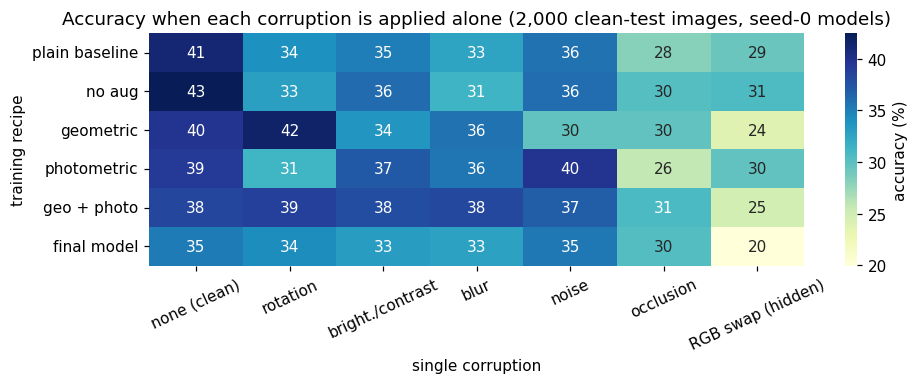

In [11]:
sub = np.concatenate([np.random.RandomState(7).choice(np.where(yte_all == c)[0], 200, replace=False) for c in range(10)])
Xs, ys = X_clean[sub], y_test[sub]
single = {"none (clean)": Xs}
for nm, comp in (("rotation", "rot"), ("bright./contrast", "bc"), ("blur", "blur"), ("noise", "noise"), ("occlusion", "occ"), ("RGB swap (hidden)", "swap")):
    single[nm] = corrupt(Xs, 11, comps=(comp,), p_blur=1.0, p_noise=1.0, p_swap=1.0)[0]
cfgs = [("plain baseline", "baseline"), ("no aug", "noaug"), ("geometric", "geo"), ("photometric", "photo"), ("geo + photo", "geo_photo"), ("final model", FINAL_KEY)]
sg = pd.DataFrame({n: {c: 100 * accuracy(predict(load_model(RUNS[f"{k}|0"]), X), ys) for c, X in single.items()} for n, k in cfgs}).T
fig, ax = plt.subplots(figsize=(9, 3.6))
sns.heatmap(sg, annot=True, fmt=".0f", cmap="YlGnBu", ax=ax, cbar_kws={"label": "accuracy (%)"}); ax.grid(False)
ax.set_title("Accuracy when each corruption is applied alone (2,000 clean-test images, seed-0 models)"); ax.set_xlabel("single corruption"); ax.set_ylabel("training recipe")
plt.xticks(rotation=25); plt.tight_layout(); plt.savefig("figures/single_corruptions.png", bbox_inches="tight"); plt.show()

**Which augmentation gave the largest gain, and which corruption does it match?** The combination of geometric and photometric augmentation (+4.0 over "No augmentation"). The heat-map above (each corruption applied alone) shows the matching:
* **rotation:** 33 % without augmentation : **42 % with geometric augmentation (+9)**, the clearest match: rotation + translation augmentation directly covers the ±25° rotation;
* **blur:** 31 % → 36–38 % with either augmentation group, and **noise:** 36 % → 40 % with photometric augmentation, which includes blur and noise;
* **brightness/contrast** only improves slightly (36 % → 37–38 %), because the un-augmented model is already fairly tolerant of it;
* **occlusion** is not helped by any recipe (26–31 % for every recipe), not even by Cutout, so occlusion stays the hardest listed corruption.

# Part E – Error analysis

final model (seed 0) shifted-test accuracy: 21.89%


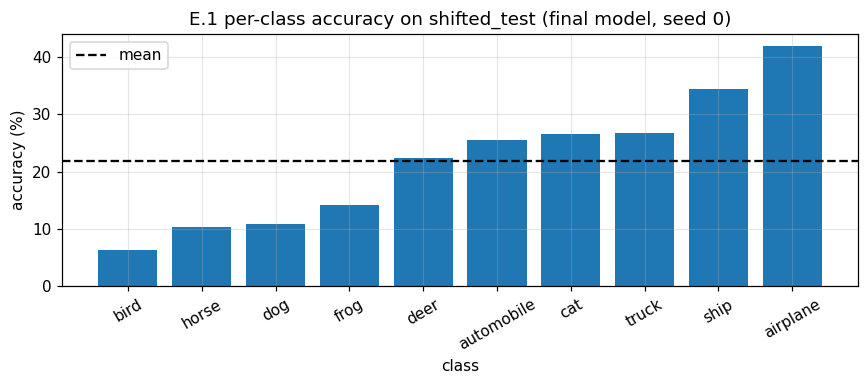

class,airplane,automobile,bird,cat,deer,dog,frog,horse,ship,truck
accuracy %,41.9,25.5,6.3,26.5,22.3,10.8,14.2,10.3,34.4,26.7


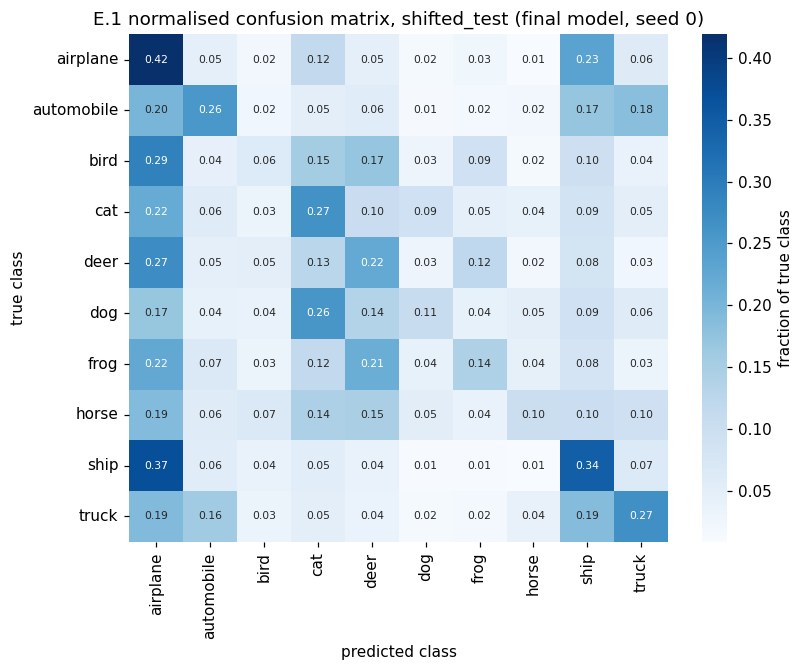

true class,predicted as,fraction of true class
ship,airplane,0.37
bird,airplane,0.29
deer,airplane,0.27
dog,cat,0.26
airplane,ship,0.23
frog,airplane,0.22
cat,airplane,0.22
frog,deer,0.21


share of all predictions per class (%): {'airplane': 25.5, 'automobile': 8.3, 'bird': 4.0, 'cat': 13.4, 'deer': 11.8, 'dog': 4.2, 'frog': 5.6, 'horse': 3.6, 'ship': 14.8, 'truck': 8.8}
cat -> dog: 0.09 | dog -> cat: 0.26


In [12]:
final_model = load_model(RUNS[f"{FINAL_KEY}|0"])
logits = predict(final_model, X_shift); prob = logits.softmax(1); pred = logits.argmax(1)
print(f"final model (seed 0) shifted-test accuracy: {100 * (pred == y_test).float().mean():.2f}%")


per_class = np.array([(pred[y_test == c] == c).float().mean().item() for c in range(10)])
order = np.argsort(per_class)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar([CLASSES[i] for i in order], 100 * per_class[order], color="tab:blue"); ax.axhline(100 * per_class.mean(), color="k", ls="--", label="mean")
ax.set_ylabel("accuracy (%)"); ax.set_xlabel("class"); ax.set_title("E.1 per-class accuracy on shifted_test (final model, seed 0)"); ax.legend()
plt.xticks(rotation=30); plt.tight_layout(); plt.savefig("figures/per_class.png", bbox_inches="tight"); plt.show()
display(pd.DataFrame({"class": CLASSES, "accuracy %": (100 * per_class).round(1)}).set_index("class").T)


cm = confusion_matrix(y_test.numpy(), pred.numpy(), normalize="true")
fig, ax = plt.subplots(figsize=(7.5, 6.2))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=ax, annot_kws={"size": 7}, cbar_kws={"label": "fraction of true class"})
ax.set_xlabel("predicted class"); ax.set_ylabel("true class"); ax.set_title("E.1 normalised confusion matrix, shifted_test (final model, seed 0)"); ax.grid(False)
plt.tight_layout(); plt.savefig("figures/confusion.png", bbox_inches="tight"); plt.show()


pairs = [(CLASSES[i], CLASSES[j], cm[i, j]) for i in range(10) for j in range(10) if i != j]
display(pd.DataFrame(sorted(pairs, key=lambda t: -t[2])[:8], columns=["true class", "predicted as", "fraction of true class"]).style.format({"fraction of true class": "{:.2f}"}).hide(axis="index"))
print("share of all predictions per class (%):", {CLASSES[i]: round(float((pred == i).float().mean() * 100), 1) for i in range(10)})
print(f"cat -> dog: {cm[3, 5]:.2f} | dog -> cat: {cm[5, 3]:.2f}")

### E.1 / E.2 – per-class accuracy and most confused classes
The final model (seed 0, 21.9 % overall) is best on **airplane (41.9 %), ship (34.4 %), truck (26.7 %), cat (26.5 %) and automobile (25.5 %)** and worst on **bird (6.3 %), horse (10.3 %), dog (10.8 %) and frog (14.2 %)**. Its predictions are skewed: **airplane** is predicted for 25.5 % of all images (10 % would be fair), ship 14.8 %, cat 13.4 %, deer 11.8 %, but horse only 3.6 %, bird 4.0 % and dog 4.2 %.

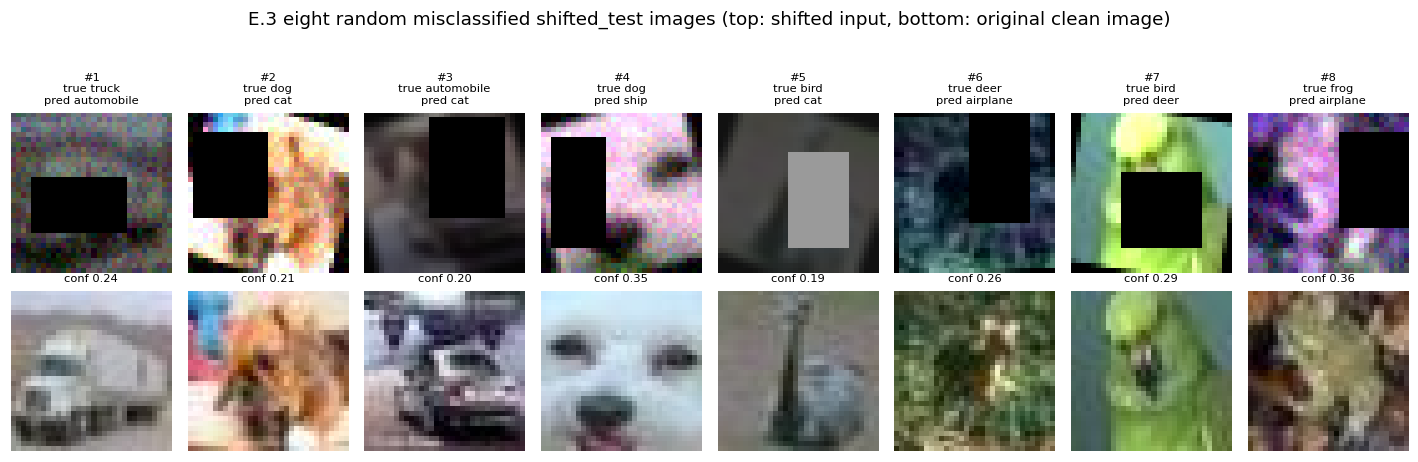

,true,pred,conf,p(true),rotation°,brightness,contrast,occluded %,blur,noise,RGB swap
#,,,,,,,,,,,
1,truck,automobile,0.24,0.17,2,0.56,1.21,20,True,True,False
2,dog,cat,0.21,0.13,-16,1.22,1.01,25,False,True,False
3,automobile,cat,0.20,0.07,13,0.57,0.91,29,True,False,True
4,dog,ship,0.35,0.06,15,1.01,1.34,24,True,True,True
5,bird,cat,0.19,0.15,-18,0.62,0.71,22,True,False,False
6,deer,airplane,0.26,0.06,4,0.75,1.35,26,False,False,True
7,bird,deer,0.29,0.22,-9,1.46,1.18,23,False,False,False
8,frog,airplane,0.36,0.02,-2,1.38,1.24,26,True,True,True


In [13]:
wrong = np.where((pred != y_test).numpy())[0]
pick = np.random.RandomState(5).choice(wrong, 8, replace=False)
fig, ax = plt.subplots(2, 8, figsize=(13, 4.1)); recs = []
for j, i in enumerate(pick):
    ax[0, j].imshow(X_shift[i].permute(1, 2, 0)); ax[1, j].imshow(X_clean[i].permute(1, 2, 0))
    ax[0, j].set_title(f"#{j + 1}\ntrue {CLASSES[y_test[i]]}\npred {CLASSES[pred[i]]}", fontsize=7.5); ax[1, j].set_title(f"conf {prob[i, pred[i]]:.2f}", fontsize=7.5)
    for r in (0, 1): ax[r, j].axis("off")
    recs.append({"#": j + 1, "true": CLASSES[y_test[i]], "pred": CLASSES[pred[i]], "conf": round(prob[i, pred[i]].item(), 2), "p(true)": round(prob[i, y_test[i]].item(), 2),
                 "rotation°": round(META["rot"][i].item()), "brightness": round(META["bright"][i].item(), 2), "contrast": round(META["contrast"][i].item(), 2),
                 "occluded %": round(100 * META["occ"][i].item()), "blur": bool(META["blur"][i]), "noise": bool(META["noise"][i]), "RGB swap": bool(META["swap"][i])})
fig.suptitle("E.3 eight random misclassified shifted_test images (top: shifted input, bottom: original clean image)", y=1.04)
plt.tight_layout(); plt.savefig("figures/errors.png", bbox_inches="tight"); plt.show()
display(pd.DataFrame(recs).set_index("#"))

### E.3 – what caused each of the 8 failures
| # | true → predicted | Visual property that caused the failure |
|---|---|---|
| 1 | truck → automobile | Dark (brightness 0.56), blurred and noisy, with a black box over the lower middle. The white truck outline is lost in grey noise, and a truck without clear size cues is easily mistaken for a car (truck/automobile is a classic confusion). |
| 2 | dog → cat | A black box (25 %) hides the left part of the face, and the image is over-exposed (1.22) and noisy and rotated −16°. What remains is a furry orange/white body with no clear face: the "furry animal" cue fits cat better (dog → cat is this model's most common dog error). |
| 3 | automobile → cat | Dark (0.57), blurred, colour channels swapped, and a box (29 %) hides the upper right of the car. The remaining dark, blurry, brownish blob has no wheels or edges, so it reads as a furry shape. |
| 4 | dog → ship | Channel swap turns the white face pink/blue-white, there is blur and noise, and a black box (24 %) hides the left side. A pale, smooth, blue-white area filling the frame looks like sea or sky, i.e. like a ship. |
| 5 | bird → cat | Dark (0.62), low contrast (0.71), blurred, rotated −18°, and a grey box (22 %) sits over the bird's central body. The original is already a grey, low-contrast bird, so almost no usable shape is left. |
| 6 | deer → airplane | Channel swap turns the green foliage into blue-teal tones, the image is darker with high contrast, and a black box (26 %) covers the top right. A small deer in blue-green surroundings now looks like a plane against a sky. |
| 7 | bird → deer | No colour change, but strongly bright (1.46) and a black box (23 %) covers the beak and chest of the green bird, the most identifying parts. This is a near miss (true-class probability 0.22 against 0.29 for the wrong class). |
| 8 | frog → airplane | Channel swap gives purple/pink tones, brightness 1.38 washes the image out, blur and noise remove the texture, and a box (26 %) covers the right side. A hazy pale-purple image resembles sky. |

**Common patterns:** (a) in every image the occluder (about 25 %) hides or cuts part of the object, (b) the hidden colour swap is present in 4 of the 8 images (#3, #4, #6, #8), and three of those four are labelled airplane or ship, as the swapped, blue/pink tones look like sky or water, (c) strong darkening or brightening plus noise or blur removes the texture the model needs, and (d) the model is never confident when wrong (0.19–0.36, with 0.02–0.22 for the true class).

### Hidden-corruption test

In [14]:
X_hidden, _ = corrupt(X_clean, SHIFT_SEED + 1, comps=("swap",), p_swap=1.0)
rows = []
for label, key in (("Plain baseline", "baseline"), (f"Final model ({FINAL_LABEL})", FINAL_KEY)):
    cl = [RUNS[f"{key}|{s}"]["clean"] for s in SEEDS]; hd = [accuracy(predict(load_model(RUNS[f"{key}|{s}"]), X_hidden), y_test) for s in SEEDS]
    rows.append({"Model": label, "Clean test": fmt((100 * np.mean(cl), 100 * np.std(cl))), "Hidden corruption only": fmt((100 * np.mean(hd), 100 * np.std(hd))),
                 "drop (points)": round(100 * (np.mean(cl) - np.mean(hd)), 1)})
display(pd.DataFrame(rows).style.hide(axis="index"))

Model,Clean test,Hidden corruption only,drop (points)
Plain baseline,41.5 ± 1.7,29.7 ± 0.4,11.800000
Final model (+ Cutout / Random Erasing),34.6 ± 0.9,19.1 ± 0.1,15.500000


### Did the augmentation generalise to the hidden corruption?
**No.** When only the RGB channel swap is applied to the clean test set, the final model falls from 34.6 % to **19.1 %** (−15.5 points), a larger drop than the plain baseline (41.5 % → 29.7 %, −11.8 points). The corruption-by-corruption heat-map shows the same thing: models trained with geometric, geometric + photometric and the final recipe do worse on the swap (24 %, 25 %, 20 %) than the model without augmentation (31 %).

Why: my colour augmentations change brightness, contrast and saturation or remove colour altogether (random grayscale, p = 0.2), but none of them re-assigns colours to the wrong channels. After a swap the image is still fully coloured but with wrong hues (green foliage turns blue, white turns pink), which the network never saw, and the augmented models lose accuracy on clean data and still use colour cues that the swap scrambles (this explanation is my interpretation and was not tested separately).

*What would address it:  add a random channel permutation or strong hue jitter to the augmentation, or use a much higher grayscale probability.

# Part F – Test-time augmentation (bonus)
The softmax outputs of **N = 8 deterministic views** are averaged: the original, a horizontal flip, four ±2 px shifts (up, down, left, right) and two flip + shift combinations. The final recipe's three seeds are evaluated on the shifted test set.

In [15]:
def shift(x, dx, dy):
    p = F.pad(x, (2, 2, 2, 2)); return p[:, :, 2 + dy:34 + dy, 2 + dx:34 + dx]
VIEWS = [lambda x: x, lambda x: x.flip(3), lambda x: shift(x, 2, 0), lambda x: shift(x, -2, 0), lambda x: shift(x, 0, 2), lambda x: shift(x, 0, -2),
         lambda x: shift(x.flip(3), 2, 0), lambda x: shift(x.flip(3), -2, 0)]

@torch.no_grad()
def predict_tta(model, X):
    model.eval(); out = 0
    for v in VIEWS: out = out + torch.cat([model(v(X[i:i + 1000])).softmax(1) for i in range(0, len(X), 1000)])
    return out / len(VIEWS)

rows = []
for s in SEEDS:
    m = load_model(RUNS[f"{FINAL_KEY}|{s}"])
    t0 = time.time(); a1 = accuracy(predict(m, X_shift), y_test); t1 = time.time() - t0
    t0 = time.time(); a8 = accuracy(predict_tta(m, X_shift), y_test); t8 = time.time() - t0
    rows.append(dict(seed=s, single_view=100 * a1, TTA_8_views=100 * a8, change=100 * (a8 - a1), time_1_view_s=t1, time_8_views_s=t8))
tta = pd.DataFrame(rows); display(tta.round(2).style.hide(axis="index"))
print(f"shifted test: {tta.single_view.mean():.2f} ± {tta.single_view.std(ddof=0):.2f}  ->  {tta.TTA_8_views.mean():.2f} ± {tta.TTA_8_views.std(ddof=0):.2f}   (change {tta.change.mean():+.2f} points)")
print(f"inference cost: {len(VIEWS)} forward passes per image = {(tta.time_8_views_s / tta.time_1_view_s).mean():.1f}x the time of a single pass")

seed,single_view,TTA_8_views,change,time_1_view_s,time_8_views_s
0,21.890000,21.860000,-0.030000,14.280000,121.500000
1,21.710000,21.630000,-0.080000,14.290000,120.460000
2,21.400000,21.220000,-0.180000,14.510000,121.300000


shifted test: 21.67 ± 0.20  ->  21.57 ± 0.26   (change -0.10 points)
inference cost: 8 forward passes per image = 8.4x the time of a single pass


### Result
Averaging the softmax over 8 deterministic views **did not help**: shifted-test accuracy changed from **21.67 ± 0.20 % to 21.57 ± 0.26 %** (**−0.10 points**), at **8 forward passes per image, about 8.4× the inference time**. The model is already trained with flips and shifts, and its main errors are systematic (occlusion, hue changes) rather than the random view-to-view variance that averaging removes, so test-time augmentation is not worth the 8× cost for this model.

# Final summary

In [16]:
fs, sb = summarize(FINAL_KEY), summarize("baseline")
print(f"FINAL MODEL: {FINAL_LABEL}")
print(f"parameters: {PARAMS:,} | lr {BEST_LR} | weight decay {BEST_WD} | dropout 0.3 | 60 epochs, cosine schedule, best-validation checkpoint")
print(f"shifted-test accuracy: {fmt(fs['shifted'])} %  |  clean-test accuracy: {fmt(fs['clean'])} %  |  validation: {fmt(fs['val'])} %  (mean ± std, 3 seeds)")
print(f"plain baseline shifted-test accuracy: {fmt(sb['shifted'])} %  ->  improvement: {fs['shifted'][0] - sb['shifted'][0]:+.1f} points")

FINAL MODEL: + Cutout / Random Erasing
parameters: 39,226 | lr 0.003 | weight decay 0.0001 | dropout 0.3 | 60 epochs, cosine schedule, best-validation checkpoint
shifted-test accuracy: 21.7 ± 0.2 %  |  clean-test accuracy: 34.6 ± 0.9 %  |  validation: 34.7 ± 1.7 %  (mean ± std, 3 seeds)
plain baseline shifted-test accuracy: 17.0 ± 0.9 %  ->  improvement: +4.6 points


## Final summary
* **Final test score (shifted test):** **21.7 ± 0.2 %** (mean ± std over 3 seeds); clean test 34.6 ± 0.9 %; validation 34.7 ± 1.7 %. The plain baseline scored 17.0 ± 0.9 % on the shifted test (clean 41.5 ± 1.7 %).
* **Configuration:** the 39,226-parameter CNN (stem → 2 Inception modules → global average pooling → dropout 0.3 → linear), AdamW with lr 0.003 and weight decay 0.0001 (chosen on validation), cosine schedule, batch 32, 60 epochs, best-validation checkpoint, on-the-fly geometric + photometric + Cutout augmentation.
* **Change that contributed most:** adding **geometric and photometric augmentation together** (+4.0 points over the regularized no-augmentation model; each alone gave +1.7 and +0.6).
* **Limits.** The gain (+4.6 over the baseline) is real but modest. Occlusion is not helped by any recipe, the hidden colour corruption is not handled at all, and heavier augmentation (CutMix) underfits this small model. Differences of about one point between the later ablation rows are within seed noise.
* **Rules check:** no pretrained weights · 39,226 ≤ 1,000,000 parameters · Inception modules · 400/100 split, tuning on validation only · augmentation on the fly, training data only · 60 epochs maximum, fixed seeds, 3 seeds with mean ± std.